In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report

In [6]:
df = pd.read_csv("Unified_Leads.csv")
df

,Name,contact_number,Contact_email,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,last_call_time,references,campaign_name,source_type,source_name
0,Anjali Singh,9931980478,anjali.singh878@hotmail.com,03-02-2026 22:31,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
1,Kiran Bose,6474315136,kiran.bose601@example.com,03-02-2026 21:46,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS
2,Karthik Malhotra,6753707898,karthik.malhotra329@example.com,03-02-2026 21:28,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
3,Anjali Sharma,9439163624,anjali.sharma85@example.com,03-02-2026 19:59,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
4,Sneha Kapoor,9878269840,sneha.kapoor46@gmail.com,03-02-2026 19:19,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27370,Rohit Reddy,6992973331,rohit.reddy220@hotmail.com,02-06-2025 13:14,02-06-2025 14:46,CLOSED,LOST,not-interested,Riswana,02-06-2025 14:46,2:46 PM,NaN,Business Accounting,INSTAGRAM,INSTAGRAM
27371,Kiran Shetty,9410734029,kiran.shetty925@outlook.com,02-06-2025 13:05,NaN,CLOSED,LOST,lost-to-competition,Anshad,NaN,NaN,NaN,Business Accounting,INSTAGRAM,INSTAGRAM
27372,Neha Shetty,9508547875,neha.shetty6@example.com,02-06-2025 12:39,02-06-2025 13:13,CLOSED,CONVERTED,NaN,Anshad,02-06-2025 13:13,1:13 PM,NaN,Business Accounting,INSTAGRAM,INSTAGRAM
27373,Nikhil Yadav,7870690595,nikhil.yadav620@outlook.com,02-06-2025 12:35,02-06-2025 13:01,RESCHEDULED BY EXECUTIVE,Follow Up Required,cold,Anshad,02-06-2025 13:01,1:01 PM,NaN,Business Accounting,INSTAGRAM,INSTAGRAM


In [13]:
# Data preprocessing
df.isnull().sum()
df.drop_duplicates(inplace=True)
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
df.drop(['Name', 'Phone Number', 'Email'], axis=1, errors='ignore', inplace=True)
le = LabelEncoder()
for col in cat_cols:
    if col in df.columns:
        df[col] = le.fit_transform(df[col])
        
df.drop_duplicates(inplace=True)
df.info()
df.head()
df.drop('references', axis=1, inplace=True)

C:\Users\roshi\AppData\Local\Temp\ipykernel_13516\130611229.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


<class 'pandas.DataFrame'>
RangeIndex: 27375 entries, 0 to 27374
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   contact_number      27375 non-null  int64  
 1   Contact_email       27375 non-null  int64  
 2   creation_date       27375 non-null  int64  
 3   first_call_attempt  27375 non-null  int64  
 4   lead_status         27375 non-null  int64  
 5   lead_stage          27375 non-null  int64  
 6   lead_tag            27375 non-null  int64  
 7   assigned_to         27375 non-null  int64  
 8   last_call_date      27375 non-null  int64  
 9   last_call_time      27375 non-null  int64  
 10  references          0 non-null      float64
 11  campaign_name       27375 non-null  int64  
 12  source_type         27375 non-null  int64  
 13  source_name         27375 non-null  int64  
dtypes: float64(1), int64(13)
memory usage: 2.9 MB


,contact_number,Contact_email,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,last_call_time,references,campaign_name,source_type,source_name
0,9931980478,4092,1269,10328,4,3,5,4,10427,454,NaN,5,2,10
1,6474315136,9622,1268,10328,4,3,5,4,10427,454,NaN,5,0,9
2,6753707898,7558,1267,10328,4,3,5,4,10427,454,NaN,5,2,10
3,9439163624,3972,1266,10328,4,3,5,4,10427,454,NaN,5,2,10
4,9878269840,23702,1265,10328,4,3,5,4,10427,454,NaN,5,2,10


<class 'pandas.DataFrame'>
RangeIndex: 27375 entries, 0 to 27374
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   contact_number      27375 non-null  int64  
 1   Contact_email       27375 non-null  int64  
 2   creation_date       27375 non-null  int64  
 3   first_call_attempt  27375 non-null  int64  
 4   lead_status         27375 non-null  int64  
 5   lead_stage          27375 non-null  int64  
 6   lead_tag            27375 non-null  int64  
 7   assigned_to         27375 non-null  int64  
 8   last_call_date      27375 non-null  int64  
 9   last_call_time      27375 non-null  int64  
 10  references          0 non-null      float64
 11  campaign_name       27375 non-null  int64  
 12  source_type         27375 non-null  int64  
 13  source_name         27375 non-null  int64  
dtypes: float64(1), int64(13)
memory usage: 2.9 MB


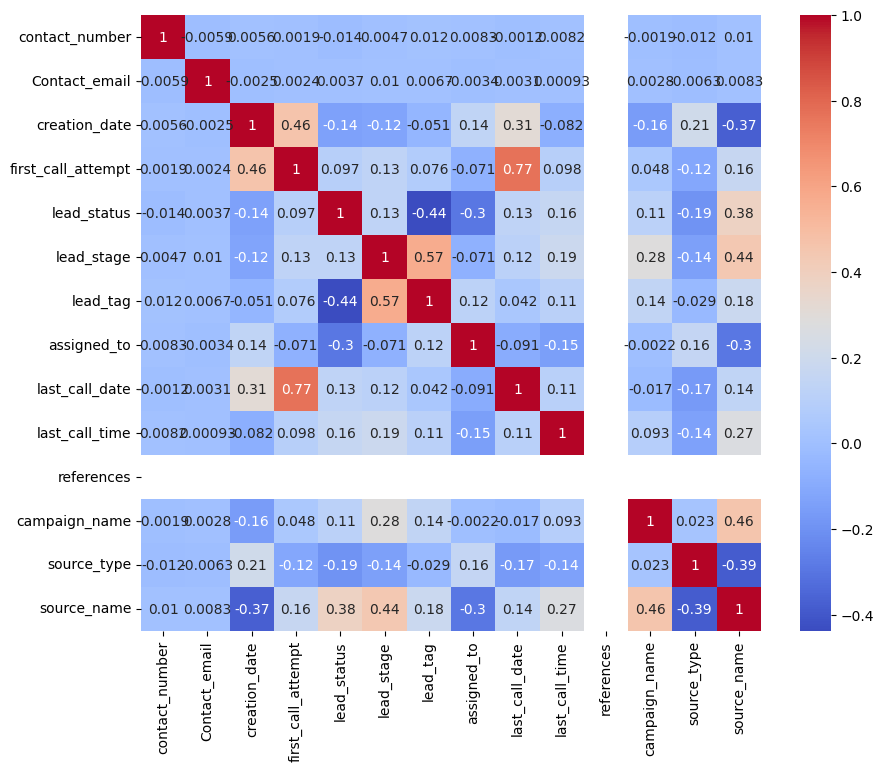

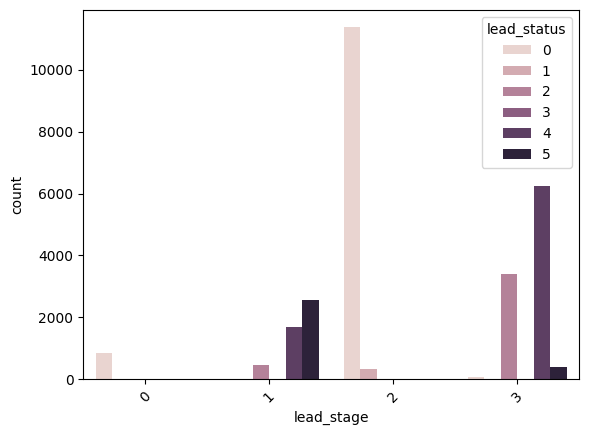

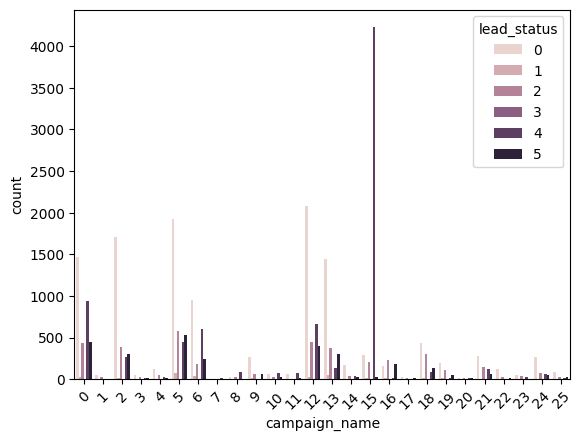

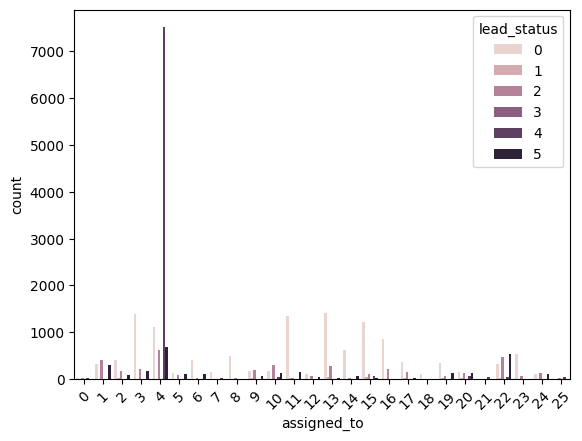

In [19]:
#Exploratory Data Analysis
df.head()
df.info()
df.describe()

df['lead_status'].value_counts()

df['lead_status'].value_counts(normalize=True) * 100

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

sns.countplot(x='lead_stage', hue='lead_status', data=df)
plt.xticks(rotation=45)
plt.show()

sns.countplot(x='campaign_name', hue='lead_status', data=df)
plt.xticks(rotation=45)
plt.show()

sns.countplot(x='assigned_to', hue='lead_status', data=df)
plt.xticks(rotation=45)
plt.show()

In [15]:
df.columns

Index(['contact_number', 'Contact_email', 'creation_date',
       'first_call_attempt', 'lead_status', 'lead_stage', 'lead_tag',
       'assigned_to', 'last_call_date', 'last_call_time', 'references',
       'campaign_name', 'source_type', 'source_name'],
      dtype='str')

In [47]:
#Model development
X = df.drop('lead_status', axis=1)
y = df['lead_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

rf = RandomForestClassifier()
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [53]:
#Model Evaluation
pred = rf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average='weighted'))
print("Recall:", recall_score(y_test, pred, average='weighted'))
print("F1 Score:", f1_score(y_test, pred, average='weighted'))

Accuracy: 0.9280365296803653
Precision: 0.9147191446350378
Recall: 0.9280365296803653
F1 Score: 0.9208872578998767
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      2463
           1       0.00      0.00      0.00        73
           2       0.84      0.87      0.85       769
           4       0.93      0.95      0.94      1555
           5       0.87      0.77      0.82       615

    accuracy                           0.93      5475
   macro avg       0.72      0.72      0.72      5475
weighted avg       0.91      0.93      0.92      5475



C:\Users\roshi\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\roshi\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\roshi\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [61]:
new_lead = X.iloc[[0]]
prediction = rf.predict(new_lead)
print("Predicted Lead Status:", prediction[0])

Predicted Lead Status: 4
